# Minería de Datos – Práctica 3.2 Asociación
## Equipo 7
**Integrantes:** Rafael Ortega de la Paz, Claudio Flores García, Barvara Caridad Juarez Valdivia

**Objetivo:** encontrar las asociaciones de productos más significativas en las ventas para diseñar promociones:
- **Requerimiento A:** en general (todos los productos).
- **Requerimiento B:** en específico para **Comidas Preparadas**.

**Algoritmos:** Apriori y FP-Growth (librería `mlxtend`).

In [1]:
# Instalar mlxtend solo si falta
# %pip install -q mlxtend  (descomentar en Colab)

In [2]:
import os, time, timeit, warnings, datetime
warnings.filterwarnings('ignore')

# Ocultar el aviso interno de Colab "datetime.utcnow() is deprecated" (no afecta resultados)
try:
    import jupyter_client.session as _jcs
    _jcs.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)
except Exception:
    pass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

## 1. Caso de negocio

La empresa vende productos de consumo (carnes frías, quesos, yoghurt, cremas, comidas preparadas, etc.)
a empleados de un grupo corporativo. Cada **transacción** (ticket) agrupa los productos que un cliente compró juntos.

**Pregunta de negocio:** ¿qué productos se compran juntos con más frecuencia de lo que se esperaría por azar?
Con esas asociaciones se pueden diseñar **promociones cruzadas** (paquetes, descuentos en el segundo producto,
acomodo en catálogo o tienda).

- **Requerimiento A – En general:** descubrir las asociaciones más fuertes entre **todas** las líneas de producto,
  para promociones generales y combos.
- **Requerimiento B – Comidas Preparadas:** descubrir con qué productos se compran las **comidas preparadas**
  (flautas, burritos, pizzas, pollo, etc.) para (1) ofrecerlas a quien compra otros productos y
  (2) ofrecer complementos a quien ya las compra.

**Conceptos clave:**
- **Soporte:** % de tickets que contienen el conjunto de productos.
- **Confianza (A → B):** de los tickets con A, % que también tienen B.
- **Lift (A → B):** confianza ÷ soporte de B. **Lift > 1** = se compran juntos más de lo esperado por azar; lift = 1 no hay relación.
- **Antecedente → Consecuente:** "si el cliente compra el antecedente, es probable que compre el consecuente".

## 2. Carga, limpieza y elección de variables

In [3]:
# En Colab, suban el archivo con el ícono de carpeta; queda en /content/
RUTA = '/content/Transacciones_de_ventas Practica.csv'
if not os.path.exists(RUTA):
    RUTA = 'Transacciones_de_ventas Practica.csv'
df = pd.read_csv(RUTA, encoding='cp1252')
print('Registros:', df.shape[0], '| Columnas:', df.shape[1])
df.head(3)

Registros: 58903 | Columnas: 33


,Sector,Tipo,Linea,Sublinea,Presentacion,Gramaje,Empresa,Año,Fecha,Cliente,...,Antiguedad,Edad,Edad_Rango,Escolaridad,Estado_Civil,Estado,Sexo,Funcion,Grupo,Reg
0,OTROS,PROLIVO,ACEITES Y MANTECAS,ACEITE DE OLIVA,PAQUETERIA,2.290,957936 ALFA TORRE,2015,04-12-15,126306 LAURA IS,...,27,46,40 - 49,Sin asignar,Casado,Nuevo Leon,Femenino,GENERICO,EMPLEADOS,1
1,OTROS,PROLIVO,ACEITES Y MANTECAS,ACEITE DE OLIVA,PAQUETERIA,2.290,957936 ALFA TORRE,2016,14-01-16,206654 ROBERTO,...,2,25,< 30,Licenciatura,Soltero,Nuevo Leon,Masculino,EMPLEADO A,EMPLEADOS,1
2,OTROS,PROLIVO,ACEITES Y MANTECAS,ACEITE DE OLIVA,PAQUETERIA,2.290,303012 CORPORATIVO BETA COMERCIAL,2016,13-06-16,203171 LILIANA,...,2,29,< 30,Licenciatura,Soltero,Nuevo Leon,Femenino,OFICINISTA B,EMPLEADOS,1


In [4]:
print('Valores nulos       :', int(df.isna().sum().sum()))
print('Filas duplicadas    :', int(df.duplicated().sum()))
print('Tickets (Transaccion):', df['Transaccion'].nunique())
print('Productos distintos :', df['Descripcion'].nunique())
print('\nProductos por ticket:')
print(df.groupby('Transaccion').size().describe().round(2))

Valores nulos       : 0
Filas duplicadas    : 0
Tickets (Transaccion): 11344
Productos distintos : 469

Productos por ticket:
count   11,344.000
mean         5.190
std          4.220
min          1.000
25%          2.000
50%          4.000
75%          7.000
max         52.000
dtype: float64


In [5]:
# Limpieza
datos = df.drop_duplicates().copy()
for c in ['Sector', 'Linea', 'Sublinea', 'Descripcion']:
    datos[c] = datos[c].astype(str).str.strip()

# Algunos textos traen acentos mal codificados (ej. 'Ã‘'); se corrigen
def corregir(t):
    try:
        return t.encode('cp1252').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return t
datos['Descripcion'] = datos['Descripcion'].apply(corregir)

# Nombre más claro para una línea de quesos (Oaxaca / Asadero)
datos['Linea'] = datos['Linea'].replace({'PASTA_ace': 'Q-OAXACA/ASADERO'})
print('Registros limpios:', len(datos))

Registros limpios: 58903


### 2.1 Variables elegidas

| Variable | Uso |
|---|---|
| **Transaccion** | Identifica la **canasta** (ticket): los productos con el mismo número se compraron juntos |
| **Linea** | El **producto** a analizar, a nivel línea (JAMONES, Q-FRESCOS, FLAUTAS…) |
| **Sector** | Para identificar los productos de **COMIDAS PREPARADAS** (requerimiento B) |
| **Descripcion** | Nivel de producto individual, para el análisis detallado de comidas preparadas |

No se usan cantidad, precio ni datos del cliente: la asociación solo considera **qué** productos aparecen juntos en un ticket.

In [6]:
def canastas(data, col):
    """Convierte las ventas en una matriz ticket x producto (True/False)."""
    listas = data.groupby('Transaccion')[col].apply(lambda s: sorted(set(s))).tolist()
    te = TransactionEncoder()
    return pd.DataFrame(te.fit(listas).transform(listas), columns=te.columns_)

def reglas(itemsets, n_tickets, metric='confidence', min_threshold=0.5):
    """association_rules compatible con versiones nuevas y viejas de mlxtend."""
    try:
        r = association_rules(itemsets, num_itemsets=n_tickets, metric=metric, min_threshold=min_threshold)
    except TypeError:
        r = association_rules(itemsets, metric=metric, min_threshold=min_threshold)
    r = r.copy()
    r['Antecedente'] = r['antecedents'].apply(lambda s: ', '.join(sorted(s)))
    r['Consecuente'] = r['consequents'].apply(lambda s: ', '.join(sorted(s)))
    return r

COLS = ['Antecedente', 'Consecuente', 'support', 'confidence', 'lift']

### 2.2 Impacto del nivel de detalle de la variable producto
Antes de elegir la variable, se compara qué pasa si el "producto" se define por Sector, Línea, Sublínea o Descripción.

In [7]:
comp = []
for col in ['Sector', 'Linea', 'Sublinea', 'Descripcion']:
    X = canastas(datos, col)
    f = fpgrowth(X, min_support=0.05, use_colnames=True)
    comp.append({'Variable': col, 'Productos distintos': X.shape[1],
                 'Soporte del más vendido': X.mean().max(),
                 'Itemsets frecuentes (soporte ≥ 5%)': len(f)})
pd.DataFrame(comp).set_index('Variable')

,Productos distintos,Soporte del más vendido,Itemsets frecuentes (soporte ≥ 5%)
Variable,,,
Sector,12,0.781,46
Linea,60,0.583,117
Sublinea,96,0.426,69
Descripcion,469,0.157,22


**Lectura:** con **Sector** (12 categorías) las reglas son demasiado generales ("carnes frías → quesos"); con
**Descripción** (469 productos) cada producto aparece en muy pocos tickets y casi no hay combinaciones frecuentes.
**Línea** (60) es el punto medio: suficientemente específica para una promoción ("jamón + queso fresco") y con
soporte suficiente para encontrar reglas. Por eso se elige **Linea** como variable de producto.

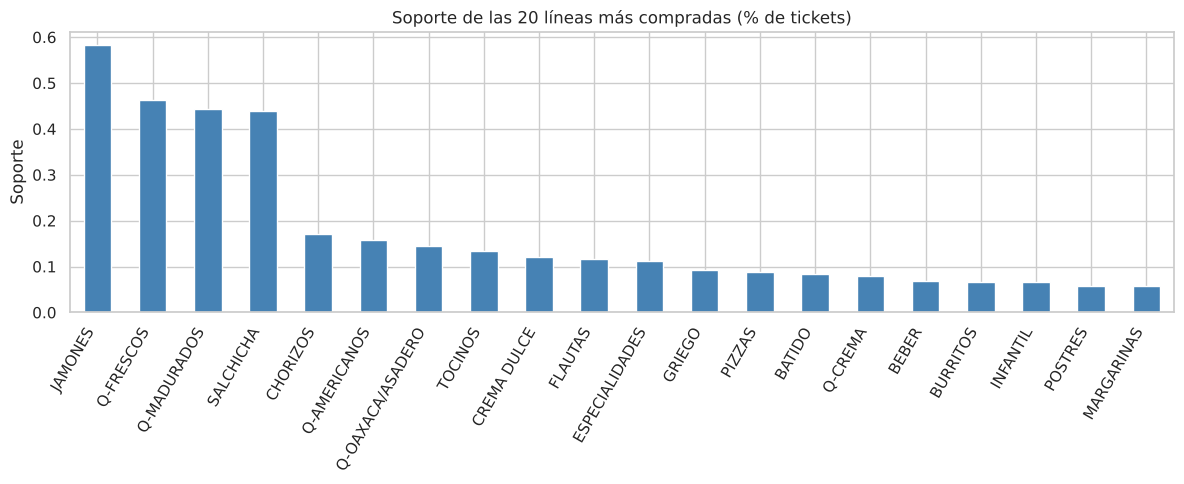

Tickets: 11344 | Líneas: 60


In [8]:
XA = canastas(datos, 'Linea')
N = len(XA)
soporte_lineas = XA.mean().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
soporte_lineas.head(20).plot.bar(color='steelblue')
plt.title('Soporte de las 20 líneas más compradas (% de tickets)'); plt.ylabel('Soporte')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()
print(f'Tickets: {N} | Líneas: {XA.shape[1]}')

---
# Requerimiento A – Asociaciones en general
### A.3 Umbral mínimo de soporte
Se prueban varios umbrales y se cuenta cuántos conjuntos frecuentes y reglas (confianza ≥ 50%) resultan.

In [9]:
filas = []
for ms in [0.10, 0.07, 0.05, 0.03, 0.02]:
    f = fpgrowth(XA, min_support=ms, use_colnames=True)
    r = reglas(f, N, 'confidence', 0.5)
    filas.append({'Soporte mínimo': ms, 'Tickets mínimos': int(ms * N),
                  'Itemsets frecuentes': len(f), 'Reglas (conf ≥ 0.5)': len(r)})
pd.DataFrame(filas).set_index('Soporte mínimo')

,Tickets mínimos,Itemsets frecuentes,Reglas (conf ≥ 0.5)
Soporte mínimo,,,
0.100,1134,31,40
0.070,794,60,90
0.050,567,117,193
0.030,340,273,552
0.020,226,478,1097


**Umbral elegido: soporte mínimo = 5%** (al menos ~567 tickets). Con 10% casi solo aparecen jamones, quesos y salchicha;
con 2–3% se generan cientos de reglas, muchas de productos poco vendidos que no justifican una promoción general.
5% conserva reglas frecuentes y manejables.

**Filtros de evaluación:** confianza ≥ 50% y lift ≥ 1.2 (la combinación ocurre al menos 20% más de lo esperado por azar).

In [10]:
SOP_A, CONF_A, LIFT_A = 0.05, 0.5, 1.2

# Apriori
t0 = time.perf_counter(); fi_ap_A = apriori(XA, min_support=SOP_A, use_colnames=True); t_ap_A = time.perf_counter() - t0
# FP-Growth
t0 = time.perf_counter(); fi_fp_A = fpgrowth(XA, min_support=SOP_A, use_colnames=True); t_fp_A = time.perf_counter() - t0

r_ap_A = reglas(fi_ap_A, N, 'confidence', CONF_A)
r_fp_A = reglas(fi_fp_A, N, 'confidence', CONF_A)
r_ap_A = r_ap_A[r_ap_A['lift'] >= LIFT_A].sort_values('lift', ascending=False)
r_fp_A = r_fp_A[r_fp_A['lift'] >= LIFT_A].sort_values('lift', ascending=False)
print(f'Apriori  : {len(fi_ap_A)} itemsets frecuentes, {len(r_ap_A)} reglas')
print(f'FP-Growth: {len(fi_fp_A)} itemsets frecuentes, {len(r_fp_A)} reglas')

Apriori  : 117 itemsets frecuentes, 184 reglas
FP-Growth: 117 itemsets frecuentes, 184 reglas


### A.4 Reglas: antecedente y consecuente
**Top 15 por lift (Apriori):**

In [11]:
r_ap_A[COLS].head(15).reset_index(drop=True)

,Antecedente,Consecuente,support,confidence,lift
0,"CHORIZOS, Q-MADURADOS","Q-FRESCOS, SALCHICHA",0.053,0.576,2.191
1,"CREMA DULCE, JAMONES","Q-FRESCOS, SALCHICHA",0.054,0.563,2.141
2,"Q-AMERICANOS, Q-MADURADOS","Q-FRESCOS, SALCHICHA",0.050,0.558,2.121
3,"CHORIZOS, JAMONES","Q-FRESCOS, SALCHICHA",0.078,0.555,2.109
4,"JAMONES, Q-OAXACA/ASADERO","Q-FRESCOS, SALCHICHA",0.060,0.548,2.084
5,"JAMONES, Q-AMERICANOS","Q-FRESCOS, SALCHICHA",0.069,0.530,2.014
6,"CHORIZOS, Q-FRESCOS","JAMONES, SALCHICHA",0.078,0.671,2.004
7,CREMA DULCE,"Q-FRESCOS, SALCHICHA",0.062,0.516,1.961
8,"CHORIZOS, Q-MADURADOS","JAMONES, SALCHICHA",0.060,0.656,1.958
9,CHORIZOS,"Q-FRESCOS, SALCHICHA",0.088,0.515,1.957


**Reglas simples (un producto → un producto), ordenadas por confianza** — las más fáciles de convertir en promoción:

In [12]:
simples_A = r_ap_A[(r_ap_A['antecedents'].apply(len) == 1) & (r_ap_A['consequents'].apply(len) == 1)]
simples_A.sort_values('confidence', ascending=False)[COLS].head(15).reset_index(drop=True)

,Antecedente,Consecuente,support,confidence,lift
0,Q-AMERICANOS,JAMONES,0.131,0.826,1.416
1,CHORIZOS,JAMONES,0.140,0.818,1.403
2,INFANTIL,JAMONES,0.052,0.793,1.360
3,CREMA DULCE,JAMONES,0.095,0.786,1.349
4,BEBER,JAMONES,0.054,0.782,1.342
5,SALCHICHA,JAMONES,0.335,0.763,1.308
6,BATIDO,JAMONES,0.063,0.762,1.308
7,Q-OAXACA/ASADERO,JAMONES,0.110,0.757,1.298
8,Q-FRESCOS,JAMONES,0.349,0.754,1.294
9,GRIEGO,JAMONES,0.070,0.754,1.294


**Las mismas reglas con FP-Growth (top 10 por lift):**

In [13]:
r_fp_A[COLS].head(10).reset_index(drop=True)

,Antecedente,Consecuente,support,confidence,lift
0,"CHORIZOS, Q-MADURADOS","Q-FRESCOS, SALCHICHA",0.053,0.576,2.191
1,"CREMA DULCE, JAMONES","Q-FRESCOS, SALCHICHA",0.054,0.563,2.141
2,"Q-AMERICANOS, Q-MADURADOS","Q-FRESCOS, SALCHICHA",0.050,0.558,2.121
3,"CHORIZOS, JAMONES","Q-FRESCOS, SALCHICHA",0.078,0.555,2.109
4,"JAMONES, Q-OAXACA/ASADERO","Q-FRESCOS, SALCHICHA",0.060,0.548,2.084
5,"JAMONES, Q-AMERICANOS","Q-FRESCOS, SALCHICHA",0.069,0.530,2.014
6,"CHORIZOS, Q-FRESCOS","JAMONES, SALCHICHA",0.078,0.671,2.004
7,CREMA DULCE,"Q-FRESCOS, SALCHICHA",0.062,0.516,1.961
8,"CHORIZOS, Q-MADURADOS","JAMONES, SALCHICHA",0.060,0.656,1.958
9,CHORIZOS,"Q-FRESCOS, SALCHICHA",0.088,0.515,1.957


### A.5 Impacto de las variables (líneas) en las reglas
Cuántas veces aparece cada línea como antecedente o consecuente en las reglas encontradas.

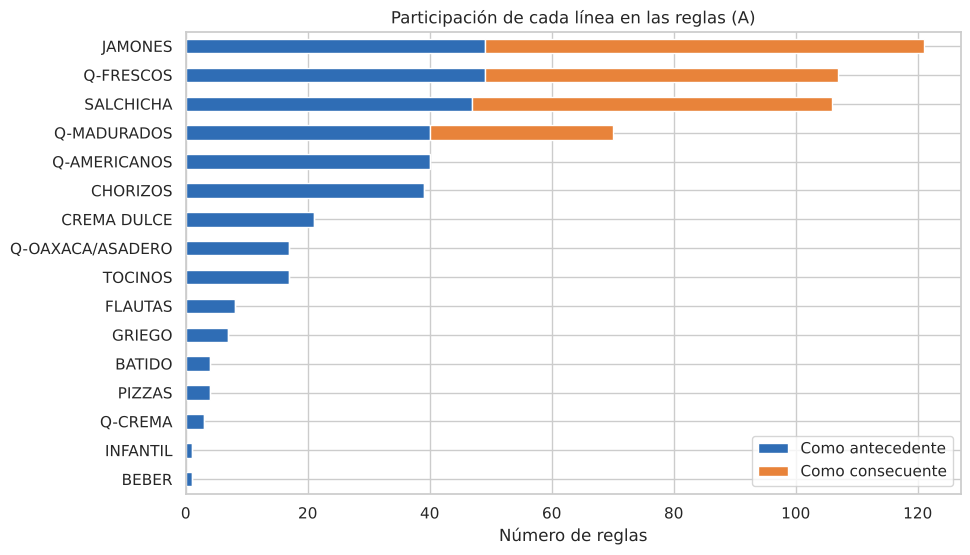

,Como antecedente,Como consecuente
JAMONES,49,72
Q-FRESCOS,49,58
SALCHICHA,47,59
Q-MADURADOS,40,30
Q-AMERICANOS,40,0
CHORIZOS,39,0
CREMA DULCE,21,0
Q-OAXACA/ASADERO,17,0
TOCINOS,17,0
FLAUTAS,8,0


In [14]:
def apariciones(r):
    a = pd.Series([i for s in r['antecedents'] for i in s]).value_counts().rename('Como antecedente')
    c = pd.Series([i for s in r['consequents'] for i in s]).value_counts().rename('Como consecuente')
    return pd.concat([a, c], axis=1).fillna(0).astype(int).sort_values('Como antecedente', ascending=False)

imp_A = apariciones(r_ap_A)
imp_A.plot.barh(stacked=True, figsize=(10, 6), color=['#2F6DB5', '#E8833A'])
plt.gca().invert_yaxis(); plt.legend(loc='lower right'); plt.title('Participación de cada línea en las reglas (A)'); plt.xlabel('Número de reglas'); plt.show()
imp_A

**Impacto:** **jamones, queso fresco, salchicha y queso madurado** forman el núcleo de las compras: son los únicos que
aparecen como **consecuente** y están en casi todas las reglas. Son los productos más vendidos (en 44–58% de los tickets),
así que funcionan como "ancla". Otras líneas (queso americano, chorizo, crema, queso Oaxaca/asadero, tocino, flautas,
yoghurt griego) solo aparecen como **antecedente**: son las que "detonan" la compra de los productos ancla.

### A.6 Evaluación con Confianza y Lift

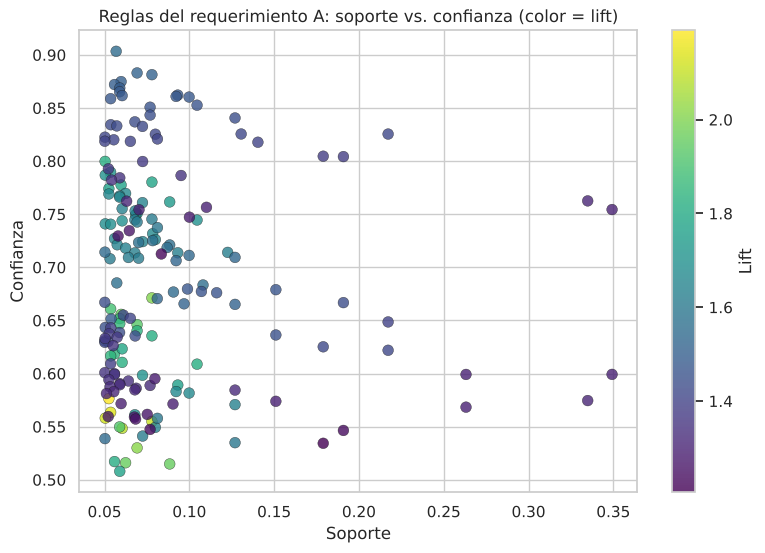

       support  confidence    lift
count  184.000     184.000 184.000
mean     0.087       0.689   1.536
std      0.055       0.101   0.210
min      0.050       0.508   1.206
25%      0.057       0.599   1.376
50%      0.068       0.679   1.484
75%      0.092       0.763   1.656
max      0.349       0.903   2.191


In [15]:
def grafica_reglas(r, titulo):
    plt.figure(figsize=(9, 6))
    sc = plt.scatter(r['support'], r['confidence'], c=r['lift'], cmap='viridis', s=60, alpha=.8, edgecolor='k', linewidth=.3)
    plt.colorbar(sc, label='Lift'); plt.xlabel('Soporte'); plt.ylabel('Confianza'); plt.title(titulo); plt.show()

grafica_reglas(r_ap_A, 'Reglas del requerimiento A: soporte vs. confianza (color = lift)')
print(r_ap_A[['support', 'confidence', 'lift']].describe().round(3))

**Evaluación:** las 184 reglas tienen confianza entre 51% y 90% y lift entre 1.21 y 2.19 (mediana 1.48): todas indican
una asociación positiva real, aunque moderada.
- Las reglas de **mayor confianza** (ej. Q-AMERICANOS → JAMONES, 83%) tienen lift moderado (1.4) porque el jamón ya está
  en 58% de los tickets: la confianza alta se debe en parte a su popularidad.
- Las reglas de **mayor lift** (≈2.2) son combinaciones de 3–4 productos, como CHORIZOS + Q-MADURADOS → Q-FRESCOS + SALCHICHA:
  se compran juntos más del doble de lo esperado por azar.

Para diseñar promociones conviene priorizar el **lift** (fuerza real de la relación) y usar la **confianza** como
probabilidad de éxito de la oferta.

### A.7 Comparación Apriori vs. FP-Growth
1. ¿Encuentran los mismos conjuntos frecuentes y reglas?
2. ¿Cuál es más rápido según el umbral de soporte?

In [16]:
def mismos(fa, ff):
    sa = {(frozenset(i), round(s, 6)) for i, s in zip(fa['itemsets'], fa['support'])}
    sf = {(frozenset(i), round(s, 6)) for i, s in zip(ff['itemsets'], ff['support'])}
    return sa == sf

def comparar_tiempos(X, soportes, max_len=None):
    filas = []
    for ms in soportes:
        ta = min(timeit.repeat(lambda: apriori(X, min_support=ms, max_len=max_len), number=1, repeat=2))
        tf = min(timeit.repeat(lambda: fpgrowth(X, min_support=ms, max_len=max_len), number=1, repeat=2))
        filas.append({'Soporte mínimo': ms, 'Itemsets': len(fpgrowth(X, min_support=ms, max_len=max_len)),
                      'Apriori (s)': ta, 'FP-Growth (s)': tf,
                      'Más rápido': 'Apriori' if ta < tf else 'FP-Growth'})
    return pd.DataFrame(filas).set_index('Soporte mínimo')

print('Mismos itemsets frecuentes:', mismos(fi_ap_A, fi_fp_A))
print('Mismas reglas             :', set(zip(r_ap_A.Antecedente, r_ap_A.Consecuente)) == set(zip(r_fp_A.Antecedente, r_fp_A.Consecuente)))
tiempos_A = comparar_tiempos(XA, [0.10, 0.05, 0.03, 0.02, 0.01])
tiempos_A

Mismos itemsets frecuentes: True
Mismas reglas             : True


,Itemsets,Apriori (s),FP-Growth (s),Más rápido
Soporte mínimo,,,,
0.100,31,0.003,0.028,Apriori
0.050,117,0.006,0.055,Apriori
0.030,273,0.016,0.057,Apriori
0.020,478,0.022,0.064,Apriori
0.010,1341,0.054,0.109,Apriori


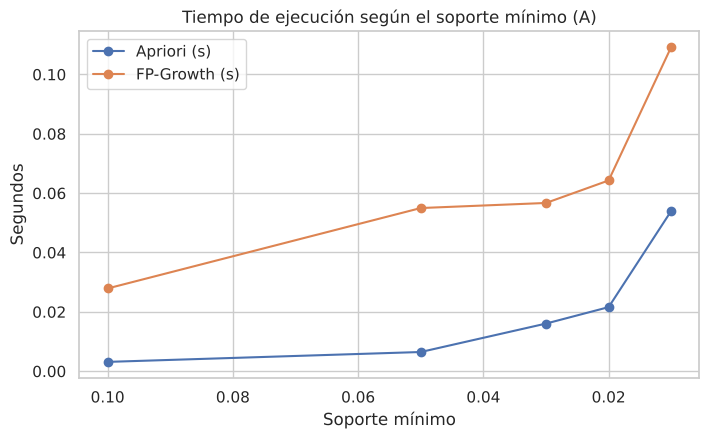

In [17]:
ax = tiempos_A[['Apriori (s)', 'FP-Growth (s)']].plot(marker='o', figsize=(8, 4.5))
ax.invert_xaxis(); ax.set_ylabel('Segundos'); ax.set_title('Tiempo de ejecución según el soporte mínimo (A)'); plt.show()

**Comentario:** ambos algoritmos encuentran **exactamente los mismos conjuntos frecuentes y las mismas reglas**,
porque los dos son exactos; solo cambia **cómo** los buscan:
- **Apriori** genera candidatos nivel por nivel (pares, tríos…) y recorre los datos en cada nivel.
- **FP-Growth** comprime los tickets en un árbol (FP-tree) y extrae los patrones sin generar candidatos.

En el requerimiento A (60 líneas, ~11 mil tickets) **Apriori fue más rápido en todos los umbrales probados**: con pocas
líneas y soportes de 1% o más hay pocos candidatos, y la implementación de Apriori de `mlxtend` los evalúa muy rápido.
FP-Growth paga el costo fijo de construir el árbol. Aun así, la brecha se reduce al bajar el soporte
(varias veces más lento con 10% y menos del doble con 1%). Ambos tardan menos de un segundo.
*(Los tiempos exactos cambian según la computadora; la tendencia se mantiene.)*

#### Uso de memoria y número de escaneos
Además del tiempo, se compara la **memoria pico** que usa cada algoritmo y el **número de veces que recorre el dataset**. Apriori recorre los tickets una vez por cada nivel (pares, tríos, etc.); FP-Growth sólo dos veces: una para contar la frecuencia de cada producto y otra para construir el árbol FP-tree, del que después extrae los patrones sin volver a leer los tickets.

In [18]:
import tracemalloc

def recursos(X, ms, max_len=None):
    """Tiempo, memoria pico y escaneos del dataset de cada algoritmo con el mismo soporte."""
    out = {}
    for nombre, fn in [('Apriori', apriori), ('FP-Growth', fpgrowth)]:
        tracemalloc.start(); t0 = time.perf_counter()
        fi = fn(X, min_support=ms, use_colnames=True, max_len=max_len)
        t = time.perf_counter() - t0
        _, pico = tracemalloc.get_traced_memory(); tracemalloc.stop()
        out[nombre] = {'Itemsets frecuentes': len(fi), 'Tiempo (s)': round(t, 3), 'Memoria pico (MB)': round(pico / 1e6, 1)}
    k = int(fi['itemsets'].apply(len).max())
    out['Apriori']['Escaneos del dataset'] = f'{k} (uno por nivel: itemsets de 1 a {k} productos)'
    out['FP-Growth']['Escaneos del dataset'] = '2 (contar productos y construir el FP-tree)'
    return pd.DataFrame(out)

print(f'Requerimiento A — soporte {SOP_A}')
recursos(XA, SOP_A)

Requerimiento A — soporte 0.05


,Apriori,FP-Growth
Itemsets frecuentes,117,117
Tiempo (s),0.015,0.447
Memoria pico (MB),7.200,1.900
Escaneos del dataset,4 (uno por nivel: itemsets de 1 a 4 productos),2 (contar productos y construir el FP-tree)


In [19]:
print('Requerimiento A — soporte 1% (más itemsets)')
recursos(XA, 0.01)

Requerimiento A — soporte 1% (más itemsets)


,Apriori,FP-Growth
Itemsets frecuentes,1341,1341
Tiempo (s),0.136,0.710
Memoria pico (MB),57.500,5.400
Escaneos del dataset,7 (uno por nivel: itemsets de 1 a 7 productos),2 (contar productos y construir el FP-tree)


**Lectura:** FP-Growth recorre el dataset sólo **2 veces**, mientras que Apriori lo recorre una vez por nivel (4 veces con soporte 5 % y 7 con soporte 1 %). Apriori también usa **mucha más memoria**: alrededor de 4 veces más con soporte 5 % y unas 10 veces más con 1 %, porque en cada nivel genera y evalúa matrices de candidatos; FP-Growth sólo guarda el árbol comprimido. En **tiempo**, sin embargo, Apriori fue más rápido (ver tabla anterior; la columna de tiempo de esta tabla incluye el costo de medir la memoria): con sólo 60 líneas y productos muy frecuentes genera pocos candidatos, y la implementación de `mlxtend` los evalúa con operaciones vectorizadas. Al bajar el soporte la brecha de tiempo se reduce y la de memoria crece; con miles de productos o soportes muy bajos FP-Growth es la opción más eficiente.

---
# Requerimiento B – Comidas Preparadas
### B.1 Caso
Las comidas preparadas aparecen en ~22% de los tickets, pero cada línea por separado tiene soporte bajo
(flautas 11.7%, burritos 6.6% y el resto menos de 2%). El objetivo es encontrar:
1. **Qué compras anticipan una comida preparada** (reglas X → Comida preparada): a quién ofrecerla.
2. **Qué se lleva quien compra comida preparada** (reglas Comida preparada → Y): qué complemento ofrecerle.
3. **Qué comidas preparadas se compran juntas** (a nivel producto): para armar paquetes.

### B.2 Variables
Mismas canastas (Transaccion) y la misma variable Linea, pero los productos del sector COMIDAS PREPARADAS se marcan
con el prefijo **`CP:`**. Esto es necesario porque algunas líneas existen en dos sectores (por ejemplo, PIZZAS está
en Comidas Preparadas y en Comidas Refrigeradas).

In [20]:
es_cp = datos['Sector'] == 'COMIDAS PREPARADAS'
datos['ItemB'] = np.where(es_cp, 'CP: ' + datos['Linea'], datos['Linea'])
XB = canastas(datos, 'ItemB')
cols_cp = [c for c in XB.columns if c.startswith('CP: ')]
print('Tickets con al menos una comida preparada:', int(XB[cols_cp].any(axis=1).sum()), f'({XB[cols_cp].any(axis=1).mean():.1%})')
XB[cols_cp].mean().sort_values(ascending=False).rename('Soporte').to_frame()

Tickets con al menos una comida preparada: 2480 (21.9%)


,Soporte
CP: FLAUTAS,0.117
CP: BURRITOS,0.066
CP: PIZZAS,0.018
CP: POLLO,0.017
CP: COMPLEMENTOS,0.017
CP: GUISOS,0.016
CP: PESCADOS,0.011
CP: LISTOS PARA CONSUMO,0.004


### B.3 Umbral mínimo de soporte

In [21]:
def tiene_cp(s):
    return any(i.startswith('CP: ') for i in s)

filas = []
for ms in [0.05, 0.03, 0.02, 0.01, 0.005]:
    f = fpgrowth(XB, min_support=ms, use_colnames=True)
    r = reglas(f, N, 'lift', 1.5)
    r = r[r['antecedents'].apply(tiene_cp) | r['consequents'].apply(tiene_cp)]
    filas.append({'Soporte mínimo': ms, 'Tickets mínimos': int(ms * N),
                  'Itemsets frecuentes': len(f), 'Reglas con CP (lift ≥ 1.5)': len(r)})
pd.DataFrame(filas).set_index('Soporte mínimo')

,Tickets mínimos,Itemsets frecuentes,Reglas con CP (lift ≥ 1.5)
Soporte mínimo,,,
0.050,567,114,2
0.030,340,269,48
0.020,226,470,154
0.010,113,1314,1458
0.005,56,3722,9466


**Umbral elegido: soporte mínimo = 1%** (al menos ~113 tickets). Con 5% solo flautas y burritos alcanzan el umbral;
1% incluye también pizzas, pollo, complementos, guisos y pescados preparados, sin bajar a combinaciones de muy pocos tickets.

**Filtros de evaluación:** como las comidas preparadas tienen soporte bajo, una confianza alta es imposible cuando
están en el consecuente; por eso se pide **lift ≥ 1.5** (al menos 50% más que el azar) y **confianza ≥ 20%**.
Para reglas con 1 o 2 productos de cada lado se limita la longitud a 3 productos (`max_len=3`), que son las
combinaciones que se pueden promocionar.

In [22]:
SOP_B, CONF_B, LIFT_B = 0.01, 0.20, 1.5

t0 = time.perf_counter(); fi_ap_B = apriori(XB, min_support=SOP_B, use_colnames=True, max_len=3); t_ap_B = time.perf_counter() - t0
t0 = time.perf_counter(); fi_fp_B = fpgrowth(XB, min_support=SOP_B, use_colnames=True, max_len=3); t_fp_B = time.perf_counter() - t0

def reglas_cp(fi):
    r = reglas(fi, N, 'confidence', CONF_B)
    r = r[(r['lift'] >= LIFT_B) & (r['antecedents'].apply(tiene_cp) | r['consequents'].apply(tiene_cp))]
    return r.sort_values('lift', ascending=False)

r_ap_B = reglas_cp(fi_ap_B)
r_fp_B = reglas_cp(fi_fp_B)
print(f'Apriori  : {len(fi_ap_B)} itemsets, {len(r_ap_B)} reglas con comidas preparadas')
print(f'FP-Growth: {len(fi_fp_B)} itemsets, {len(r_fp_B)} reglas con comidas preparadas')

Apriori  : 754 itemsets, 148 reglas con comidas preparadas
FP-Growth: 754 itemsets, 148 reglas con comidas preparadas


### B.4 Reglas: antecedente y consecuente
**1) ¿Qué compras anticipan una comida preparada? (comida preparada en el consecuente)**

In [23]:
hacia_cp = r_ap_B[r_ap_B['consequents'].apply(lambda s: all(i.startswith('CP: ') for i in s))]
hacia_cp[COLS].head(15).reset_index(drop=True)

,Antecedente,Consecuente,support,confidence,lift
0,"Q-AMERICANOS, Q-OAXACA/ASADERO",CP: BURRITOS,0.010,0.230,3.454
1,"PIZZAS, SALCHICHA",CP: BURRITOS,0.010,0.224,3.363
2,PECHUGAS RELLENAS,CP: FLAUTAS,0.010,0.373,3.181
3,PIZZAS,CP: BURRITOS,0.015,0.204,3.073
4,"JAMONES, PIZZAS",CP: BURRITOS,0.011,0.204,3.072
5,"CP: BURRITOS, SALCHICHA",CP: FLAUTAS,0.013,0.321,2.743
6,"CP: BURRITOS, JAMONES",CP: FLAUTAS,0.015,0.309,2.633
7,"BEBER, Q-MADURADOS",CP: FLAUTAS,0.011,0.306,2.608
8,CP: BURRITOS,CP: FLAUTAS,0.020,0.300,2.558
9,"PIZZAS, SALCHICHA",CP: FLAUTAS,0.013,0.296,2.527


**2) ¿Qué se lleva quien compra comida preparada? (comida preparada en el antecedente, ordenado por confianza)**

In [24]:
desde_cp = reglas(fi_ap_B, N, 'confidence', 0.5)
desde_cp = desde_cp[desde_cp['antecedents'].apply(lambda s: all(i.startswith('CP: ') for i in s))
                    & ~desde_cp['consequents'].apply(tiene_cp) & (desde_cp['lift'] > 1)]
desde_cp.sort_values('confidence', ascending=False)[COLS].head(15).reset_index(drop=True)

,Antecedente,Consecuente,support,confidence,lift
0,"CP: BURRITOS, CP: FLAUTAS",JAMONES,0.015,0.770,1.321
1,CP: PIZZAS,JAMONES,0.014,0.759,1.302
2,CP: BURRITOS,JAMONES,0.050,0.748,1.283
3,CP: FLAUTAS,JAMONES,0.083,0.713,1.223
4,CP: COMPLEMENTOS,JAMONES,0.012,0.684,1.173
5,CP: POLLO,JAMONES,0.012,0.677,1.161
6,"CP: BURRITOS, CP: FLAUTAS",SALCHICHA,0.013,0.673,1.531
7,CP: PIZZAS,SALCHICHA,0.012,0.665,1.514
8,CP: COMPLEMENTOS,Q-FRESCOS,0.011,0.648,1.400
9,CP: COMPLEMENTOS,SALCHICHA,0.011,0.633,1.441


**3) ¿Qué comidas preparadas se compran juntas? (nivel producto)**
Se toman solo los tickets con comida preparada (2,480) y como producto la **Descripción** de las comidas preparadas.
Soporte mínimo 2% de esos tickets (~50 tickets).

In [25]:
datos_cp = datos[es_cp]
X_cp = canastas(datos_cp, 'Descripcion')
N_cp = len(X_cp)
fi_cp_prod = fpgrowth(X_cp, min_support=0.02, use_colnames=True)
r_cp_prod = reglas(fi_cp_prod, N_cp, 'confidence', 0.3)
r_cp_prod = r_cp_prod[r_cp_prod['lift'] > 1].sort_values('lift', ascending=False)
print(f'Tickets con comida preparada: {N_cp} | productos: {X_cp.shape[1]} | reglas: {len(r_cp_prod)}')
r_cp_prod[COLS].reset_index(drop=True)

Tickets con comida preparada: 2480 | productos: 35 | reglas: 11


,Antecedente,Consecuente,support,confidence,lift
0,BURRITO JAMON C/QUESO 110GR CZO,BURRITO DESHEBRADA C/Chipotle 110GR CZO,0.023,0.514,6.403
1,"BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO",BURRITO DESHEBRADA 110GR CZO,0.030,0.712,4.985
2,BURRITO DESHEBRADA C/Chipotle 110GR CZO,"BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA 110GR CZO",0.030,0.372,4.681
3,"BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA 110GR CZO",BURRITO DESHEBRADA C/Chipotle 110GR CZO,0.030,0.376,4.681
4,BURRITO JAMON C/QUESO 110GR CZO,BURRITO DESHEBRADA 110GR CZO,0.029,0.661,4.628
5,"BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO",BURRITO BARBACOA 110GR CZO,0.030,0.718,4.192
6,BURRITO DESHEBRADA C/Chipotle 110GR CZO,BURRITO DESHEBRADA 110GR CZO,0.042,0.518,3.626
7,BURRITO BARBACOA 110GR CZO,BURRITO DESHEBRADA 110GR CZO,0.079,0.464,3.247
8,BURRITO DESHEBRADA 110GR CZO,BURRITO BARBACOA 110GR CZO,0.079,0.556,3.247
9,BURRITO JAMON C/QUESO 110GR CZO,BURRITO BARBACOA 110GR CZO,0.024,0.550,3.212


### B.5 Impacto de las variables (líneas) en las reglas de comidas preparadas

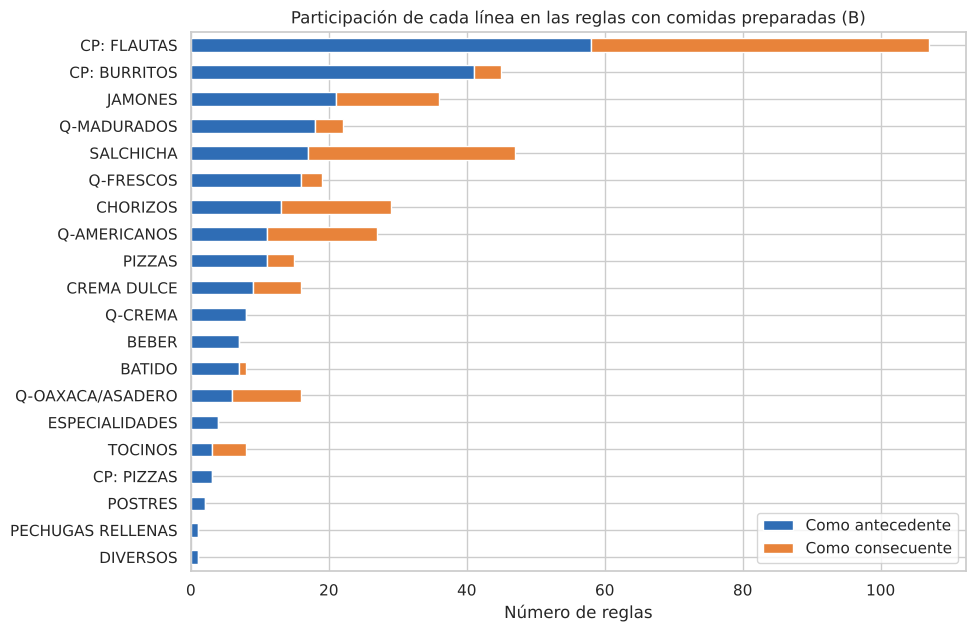

,Como antecedente,Como consecuente
CP: FLAUTAS,58,49
CP: BURRITOS,41,4
JAMONES,21,15
Q-MADURADOS,18,4
SALCHICHA,17,30
Q-FRESCOS,16,3
CHORIZOS,13,16
Q-AMERICANOS,11,16
PIZZAS,11,4
CREMA DULCE,9,7


In [26]:
imp_B = apariciones(r_ap_B)
imp_B.head(20).plot.barh(stacked=True, figsize=(10, 7), color=['#2F6DB5', '#E8833A'])
plt.gca().invert_yaxis(); plt.legend(loc='lower right'); plt.title('Participación de cada línea en las reglas con comidas preparadas (B)')
plt.xlabel('Número de reglas'); plt.show()
imp_B.head(20)

**Impacto:** **flautas y burritos** concentran casi todas las reglas, porque son las únicas comidas preparadas con
soporte suficiente (11.7% y 6.6% de los tickets); pizzas, pollo, complementos, guisos y pescados preparados casi no
aparecen. Del lado de los otros productos destacan **jamones, salchicha, quesos y chorizos** (los productos ancla) y las
**pizzas refrigeradas** (línea PIZZAS sin prefijo), que se asocian fuertemente con burritos y flautas.

### B.6 Evaluación con Confianza y Lift

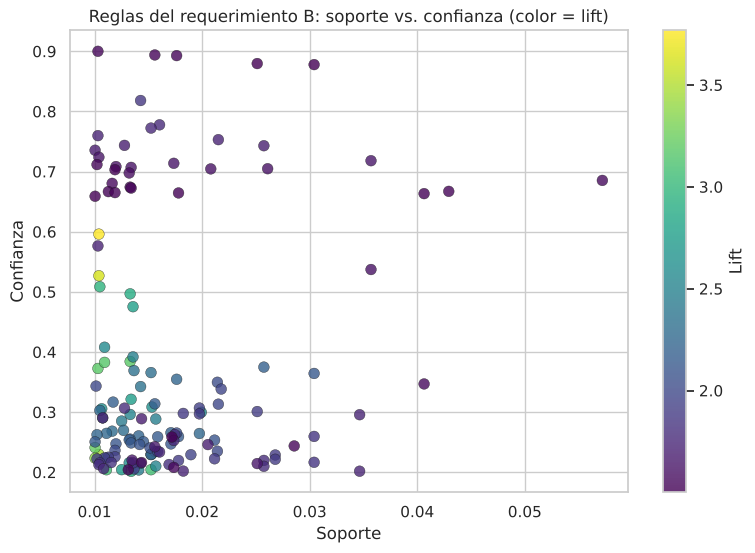

       support  confidence    lift
count  148.000     148.000 148.000
mean     0.017       0.382   2.065
std      0.008       0.207   0.505
min      0.010       0.202   1.500
25%      0.012       0.229   1.689
50%      0.014       0.287   1.920
75%      0.018       0.513   2.260
max      0.057       0.900   3.768


In [27]:
grafica_reglas(r_ap_B, 'Reglas del requerimiento B: soporte vs. confianza (color = lift)')
print(r_ap_B[['support', 'confidence', 'lift']].describe().round(3))

**Evaluación:** las 148 reglas tienen **lift más alto que en el requerimiento A** (entre 1.5 y 3.77, mediana 1.92), pero
**confianza más baja** (mediana 29%). Es lo esperado: las comidas preparadas se compran en pocos tickets, así que la
probabilidad de que alguien las lleve es baja, pero cuando aparecen ciertos productos esa probabilidad se multiplica
por 2 o 3. Para promociones de comidas preparadas el lift es la métrica clave.

### B.7 Comparación Apriori vs. FP-Growth

In [28]:
print('Mismos itemsets frecuentes:', mismos(fi_ap_B, fi_fp_B))
print('Mismas reglas             :', set(zip(r_ap_B.Antecedente, r_ap_B.Consecuente)) == set(zip(r_fp_B.Antecedente, r_fp_B.Consecuente)))
tiempos_B = comparar_tiempos(XB, [0.05, 0.02, 0.01, 0.005], max_len=3)  # mismo max_len que el análisis B
tiempos_B

Mismos itemsets frecuentes: True
Mismas reglas             : True


,Itemsets,Apriori (s),FP-Growth (s),Más rápido
Soporte mínimo,,,,
0.050,103,0.007,0.077,Apriori
0.020,334,0.011,0.086,Apriori
0.010,754,0.034,0.088,Apriori
0.005,1521,0.066,0.141,Apriori


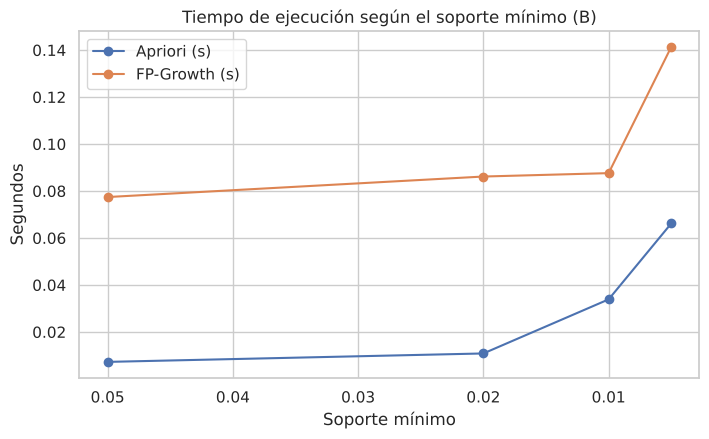

In [29]:
ax = tiempos_B[['Apriori (s)', 'FP-Growth (s)']].plot(marker='o', figsize=(8, 4.5))
ax.invert_xaxis(); ax.set_ylabel('Segundos'); ax.set_title('Tiempo de ejecución según el soporte mínimo (B)'); plt.show()

**Comentario:** de nuevo **ambos algoritmos dan exactamente los mismos conjuntos frecuentes y reglas**. En tiempo,
con este conjunto de datos **Apriori fue más rápido en todos los umbrales probados**, aunque la diferencia se reduce al
bajar el soporte. La razón es que solo hay 60 líneas de producto y las combinaciones se limitaron a 3 productos, así que
Apriori genera pocos candidatos; FP-Growth paga el costo fijo de construir su árbol. FP-Growth está pensado para escalar
mejor cuando hay **muchos productos y soportes muy bajos** (por ejemplo, analizar miles de productos individuales).
*(Los tiempos cambian según la computadora; lo importante es la tendencia.)*

In [30]:
print(f'Requerimiento B — soporte {SOP_B}, max_len=3')
recursos(XB, SOP_B, max_len=3)

Requerimiento B — soporte 0.01, max_len=3


,Apriori,FP-Growth
Itemsets frecuentes,754,754
Tiempo (s),0.060,0.609
Memoria pico (MB),56.400,5.100
Escaneos del dataset,3 (uno por nivel: itemsets de 1 a 3 productos),2 (contar productos y construir el FP-tree)


---
## Asociaciones poco obvias (nivel producto)
A nivel línea las reglas más fuertes son las esperadas (jamón, quesos, salchicha). Para buscar relaciones **menos evidentes**, que son las que aportan valor descubierto por la minería, se repite FP-Growth con la **Descripción** de cada producto (469 productos), soporte mínimo de 1 % (≈113 tickets), confianza ≥ 30 % y lift ≥ 3.

In [31]:
XP = canastas(datos, 'Descripcion')
fi_p = fpgrowth(XP, min_support=0.01, use_colnames=True)
r_p = reglas(fi_p, len(XP), 'lift', 3)
r_p = r_p[r_p['confidence'] >= 0.3].sort_values('lift', ascending=False)
print(f'Productos: {XP.shape[1]} | itemsets: {len(fi_p)} | reglas (conf ≥ 30%, lift ≥ 3): {len(r_p)}')
r_p[COLS].reset_index(drop=True)

Productos: 469 | itemsets: 227 | reglas (conf ≥ 30%, lift ≥ 3): 10


,Antecedente,Consecuente,support,confidence,lift
0,YOGHURT GRIEGO FRESA 145 GR,YOGHURT GRIEGO SELECCION DE MORAS 145 GR,0.016,0.697,30.177
1,YOGHURT GRIEGO SELECCION DE MORAS 145 GR,YOGHURT GRIEGO FRESA 145 GR,0.016,0.702,30.177
2,BURRITO DESHEBRADA 110GR CZO,BURRITO BARBACOA 110GR CZO,0.017,0.556,14.854
3,BURRITO BARBACOA 110GR CZO,BURRITO DESHEBRADA 110GR CZO,0.017,0.464,14.854
4,SALCHICHA PAVO 500GR TIPO JAL,JAMON DE PAVO VIRGINIA TIPO JAL 290 GR,0.011,0.430,4.746
5,QUESO MOLIDO NORTEÑO 170G,JAMON DE PAVO VIRGINIA TIPO JAL 290 GR,0.013,0.330,3.646
6,JAMON DE PAVO VIRGINIA TIPO JAL 290 GR,CHORIZO PAVO 200GR TIPO JAL,0.035,0.391,3.384
7,CHORIZO PAVO 200GR TIPO JAL,JAMON DE PAVO VIRGINIA TIPO JAL 290 GR,0.035,0.307,3.384
8,CREMA TIPO NOR 250GR,CHORIZO PAVO 200GR TIPO JAL,0.029,0.362,3.131
9,QUESO ASADERO .400G LVI,CHORIZO PAVO 200GR TIPO JAL,0.010,0.361,3.120


**Lectura:** aparecen relaciones que no se ven a nivel línea:
- **Yoghurt griego fresa ↔ yoghurt griego moras (145 g):** ≈70 % de confianza y lift ≈ 30; quien compra un sabor casi siempre lleva el otro. Promoción: paquete multisabor de yoghurt griego.
- **Burrito de barbacoa ↔ burrito de deshebrada:** lift ≈ 15 sobre todos los tickets; confirma la compra de burritos surtidos.
- **Marca TIPO JAL:** la salchicha de pavo lleva al jamón de pavo Virginia de la misma marca (lift ≈ 4.8), y el chorizo de pavo aparece junto a crema, queso asadero y queso molido norteño (lift ≈ 3). Indica fidelidad a la marca y una compra tipo desayuno/antojito.

## Exportación para RapidMiner (Altair AI Studio)
Se exportan las canastas en formato **una fila por ticket y una columna por línea**, con **1** si el ticket contiene la línea y **0** si no.
En RapidMiner: `Read CSV` → `Numerical to Binominal` (convierte 1/0 en true/false) → `FP-Growth` (input format: *items in dummy coded columns*) → `Create Association Rules`.

RapidMiner no incluye Apriori de forma nativa, por eso ahí se replica sólo FP-Growth; la comparación Apriori vs FP-Growth se hace en Python. Los filtros de **lift** y de **reglas con comidas preparadas** se aplicaron al revisar la tabla de reglas (ordenando por lift y filtrando la conclusión), ya que `Create Association Rules` sólo filtra por un criterio (confianza).

In [32]:
def exportar(X, nombre):
    out = X.astype(int).copy()
    out.insert(0, 'Transaccion', range(1, len(out) + 1))
    out.to_csv(nombre, index=False, encoding='utf-8')
    print(nombre, out.shape)

exportar(XA, 'canastas_A_general.csv')
exportar(XB, 'canastas_B_comidas_preparadas.csv')

try:
    from google.colab import files
    files.download('canastas_A_general.csv')
    files.download('canastas_B_comidas_preparadas.csv')
except ImportError:
    print('No es Colab; archivos guardados en:', os.getcwd())

canastas_A_general.csv (11344, 61)


canastas_B_comidas_preparadas.csv (11344, 63)
No es Colab; archivos guardados en: /tmp/claude-0/-home-claude/d11a8af2-038e-54d0-a33b-631d8fc46248/scratchpad/run2


## 8. Conclusiones de negocio

### Requerimiento A – En general
1. **Núcleo de la canasta:** jamones (58% de los tickets), queso fresco (46%), queso madurado (44%) y salchicha (44%)
   aparecen en casi todas las reglas. Son productos ancla: conviene usarlos como base de los paquetes, no descontarlos.
2. **La asociación más fuerte:** {CHORIZOS, Q-MADURADOS} → {Q-FRESCOS, SALCHICHA} con lift 2.19 y confianza 58%.
   → **Promoción "paquete desayuno":** chorizo + salchicha + queso fresco/madurado con precio especial.
3. **Reglas simples de alta confianza:** Q-AMERICANOS → JAMONES (83%), CHORIZOS → JAMONES (82%),
   CHORIZOS → SALCHICHA (71%, lift 1.63), CREMA DULCE → Q-FRESCOS (72%, lift 1.55).
   → **Promociones:** descuento en queso americano al comprar jamón ("combo sándwich"); crema + queso fresco
   ("combo antojitos"); colocar chorizo junto a salchicha y jamón.

4. **Hallazgos poco obvios (nivel producto):** los yoghurts griegos de fresa y moras se compran juntos 30 veces más que
   por azar, y los productos de pavo TIPO JAL se compran entre sí (lift hasta 4.8).
   → **Paquete multisabor de yoghurt griego** y **promoción de marca TIPO JAL** (salchicha + jamón + chorizo de pavo).

### Requerimiento B – Comidas Preparadas
1. **A quién ofrecerlas:** quien compra **pizzas refrigeradas** tiene 3 veces más probabilidad de llevar burritos
   (lift 3.07) y 2.3 veces más de llevar flautas; quien compra **pechugas rellenas** lleva flautas en 37% de los casos
   (lift 3.18). Son clientes de "comida lista para calentar".
   → **Promoción "comida rápida en casa":** pizza + burritos o pechugas rellenas + flautas.
2. **Entre comidas preparadas:** BURRITOS → FLAUTAS (confianza 30%, lift 2.56).
   → **Paquete flautas + burritos.**
3. **Qué se lleva quien compra comida preparada:** jamones (71–77%) y salchicha (59–67%, lift hasta 1.53).
   → Ubicar las comidas preparadas junto a las carnes frías, o dar un cupón de comida preparada en la compra de jamón.
4. **A nivel producto:** los burritos se compran surtidos: BARBACOA ↔ DESHEBRADA (confianza 46–56%, lift 3.25) y
   JAMÓN C/QUESO → DESHEBRADA C/CHIPOTLE (lift 6.4).
   → **Promoción "3 burritos surtidos"** con barbacoa, deshebrada y deshebrada con chipotle.

### Algoritmos
Apriori y FP-Growth producen **los mismos resultados**; la diferencia es solo de velocidad. Con estos datos (60 líneas)
Apriori fue más rápido, pero usó hasta ~10 veces más memoria y recorre el dataset una vez por nivel, mientras que
FP-Growth sólo lo recorre 2 veces. FP-Growth conviene cuando hay muchos más productos o soportes muy bajos.

### Limitaciones
Fuera de flautas y burritos, las comidas preparadas tienen soporte menor a 2%, así que generan pocas reglas. Los datos
son de 2014–2016; las asociaciones deben revisarse con datos recientes antes de lanzar las promociones.